# Ejercicio 3 · Pronóstico de la TRM: ARIMA frente a Gradient Boosting

La Tasa Representativa del Mercado (TRM) es el precio oficial del dólar en pesos colombianos. Afecta la inflación, la deuda externa, las exportaciones y los presupuestos de cualquier empresa que compre o venda en dólares, así que pronosticarla es una tarea habitual en bancos, gremios y entidades públicas.

En este ejercicio pronosticamos el **promedio mensual de la TRM** un mes adelante con dos enfoques muy distintos: un modelo ARIMA (Box-Jenkins, la tradición econométrica) y un Gradient Boosting (aprendizaje automático con rezagos como variables). Ambos se comparan contra el pronóstico más simple posible, el **paseo aleatorio** ("el mes que viene será igual a este"), que en series financieras es un rival difícil de vencer.

**Datos:** TRM diaria del Banco de la República desde el 27 de noviembre de 1991 hasta el 28 de agosto de 2026 (12.694 días), tomada del repositorio público *Time-Series-Colombia* (Especialización en Analítica Estadística, Universidad de La Salle).

In [1]:
import numpy as np
import pandas as pd
from pathlib import Path
from itertools import product
from scipy import stats
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from sklearn.ensemble import GradientBoostingRegressor
import warnings; warnings.filterwarnings('ignore')

DATOS = Path('datos')   # en Colab, sube la carpeta datos/ al entorno
SEMILLA = 42

In [2]:
# Estilo gráfico común (paleta validada para daltonismo)
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

AZUL, NARANJA, AQUA, ROJO = '#2a78d6', '#eb6834', '#1baf7a', '#e34948'
GRIS, TINTA, TINTA2 = '#898781', '#0b0b0b', '#52514e'
SEQ = LinearSegmentedColormap.from_list('azul', ['#cde2fb', '#86b6ef', '#3987e5', '#1c5cab', '#0d366b'])
DIV = LinearSegmentedColormap.from_list('div', ['#1c5cab', '#86b6ef', '#f0efec', '#ee9a99', '#b02e2e'])

mpl.rcParams.update({
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'savefig.facecolor': '#fcfcfb',
    'axes.edgecolor': '#c3c2b7', 'axes.labelcolor': TINTA2, 'text.color': TINTA,
    'xtick.color': GRIS, 'ytick.color': GRIS, 'axes.grid': True, 'grid.color': '#e1e0d9',
    'grid.linewidth': 0.6, 'axes.spines.top': False, 'axes.spines.right': False,
    'font.size': 10, 'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'figure.dpi': 110, 'lines.linewidth': 2, 'legend.frameon': False,
})

## 1. De datos diarios a una serie mensual

La TRM se publica todos los días, incluidos fines de semana y festivos (en esos días repite el valor del último día hábil). Promediamos por mes y descartamos noviembre de 1991, que solo tiene cuatro días. Agosto de 2026 queda con 28 días, lo suficiente para un promedio representativo.

416 meses, de Jan 1992 a Aug 2026


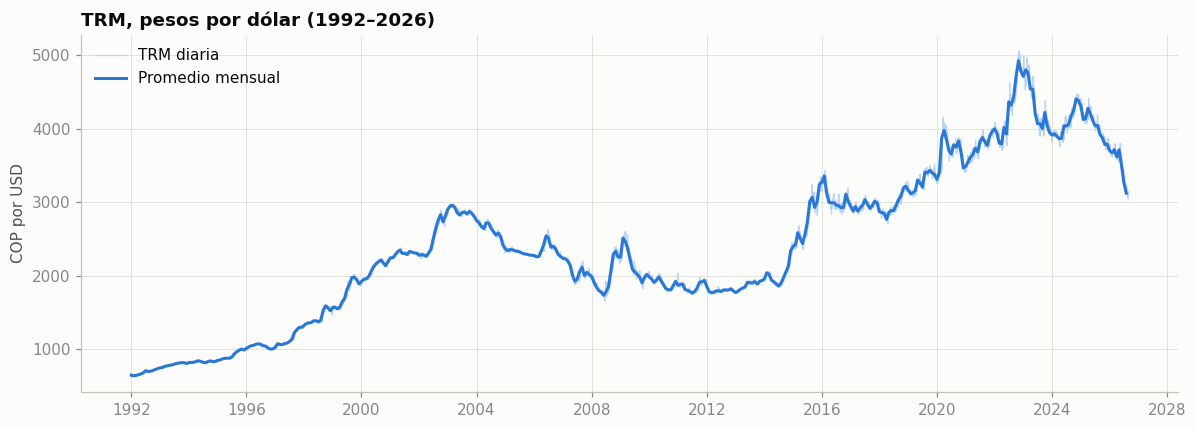

In [3]:
diaria = pd.read_csv(DATOS / 'ej3_trm_diaria.csv', parse_dates=['fecha']).set_index('fecha').trm
trm = diaria.resample('MS').mean().loc['1992-01':]
trm.index.freq = 'MS'
print(f'{len(trm)} meses, de {trm.index[0]:%b %Y} a {trm.index[-1]:%b %Y}')

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(diaria.loc['1992':], color='#b7d3f6', lw=0.8, label='TRM diaria')
ax.plot(trm, color=AZUL, lw=2, label='Promedio mensual')
ax.set(title='TRM, pesos por dólar (1992–2026)', ylabel='COP por USD')
ax.legend(loc='upper left'); plt.tight_layout(); plt.show()

Se ven los grandes episodios: la devaluación de finales de los noventa, la revaluación de 2003-2012, el salto de 2014-2015 por la caída del petróleo, el pico de 2022 y la apreciación posterior. La serie en niveles claramente no es estacionaria: su media y su varianza cambian con el tiempo.

## 2. Transformación y estacionariedad

Trabajamos con el logaritmo de la TRM. Su primera diferencia es el **retorno logarítmico mensual**, aproximadamente la variación porcentual del dólar de un mes a otro. Verificamos estacionariedad con dos pruebas complementarias: ADF (hipótesis nula: hay raíz unitaria) y KPSS (hipótesis nula: la serie es estacionaria).

,serie,ADF p-valor,KPSS p-valor,conclusión
0,log(TRM),0.1004,0.010,no estacionaria
1,Δ log(TRM),0.0000,0.065,estacionaria


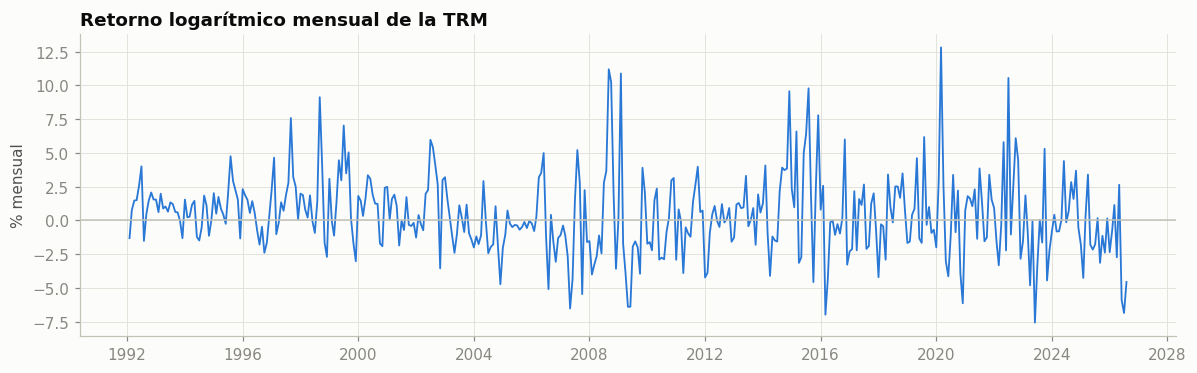

In [4]:
y = np.log(trm)
r = y.diff().dropna()

def pruebas(serie, nombre):
    adf_p = adfuller(serie, autolag='AIC')[1]
    kpss_p = kpss(serie, regression='c', nlags='auto')[1]
    return {'serie': nombre, 'ADF p-valor': round(adf_p, 4), 'KPSS p-valor': round(kpss_p, 4),
            'conclusión': 'estacionaria' if (adf_p < 0.05 and kpss_p > 0.05) else 'no estacionaria'}

display(pd.DataFrame([pruebas(y, 'log(TRM)'), pruebas(r, 'Δ log(TRM)')]))

fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(r * 100, color=AZUL, lw=1.2)
ax.axhline(0, color='#c3c2b7', lw=1)
ax.set(title='Retorno logarítmico mensual de la TRM', ylabel='% mensual')
plt.tight_layout(); plt.show()

El logaritmo no es estacionario y su primera diferencia sí, así que el orden de integración es *d* = 1. Los retornos oscilan alrededor de cero con periodos de mayor volatilidad (1998-1999, 2008, 2015, 2020, 2022).

## 3. Identificación: ACF y PACF de los retornos

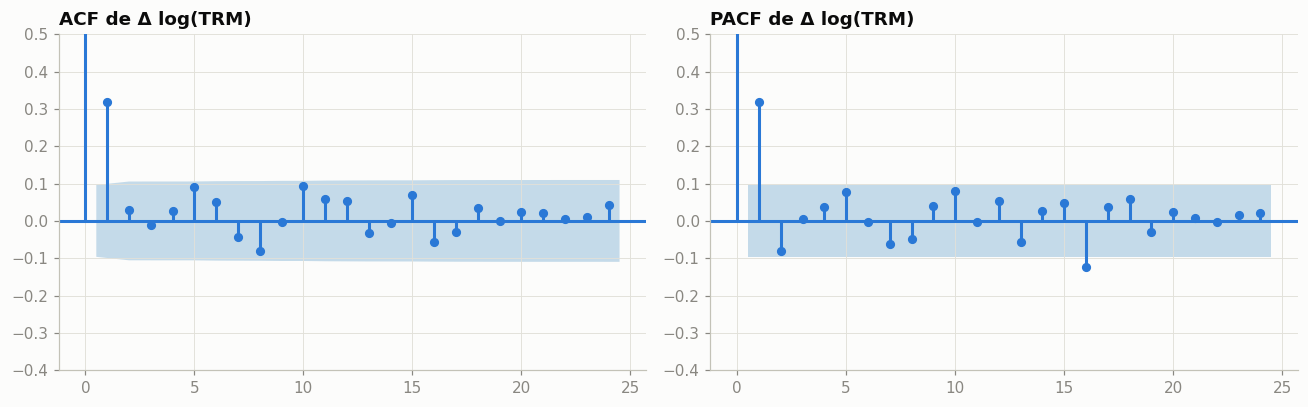

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
plot_acf(r, lags=24, ax=ax[0], color=AZUL, vlines_kwargs={'colors': AZUL}, title='ACF de Δ log(TRM)')
plot_pacf(r, lags=24, ax=ax[1], color=AZUL, vlines_kwargs={'colors': AZUL}, method='ywm', title='PACF de Δ log(TRM)')
for a in ax: a.set_ylim(-0.4, 0.5)
plt.tight_layout(); plt.show()

La ACF tiene un único pico significativo en el rezago 1 (cerca de 0,32) y luego se corta, mientras que la PACF decae alternando signo: es la firma de un proceso MA(1) en los retornos, es decir, un ARIMA(0,1,1) en el logaritmo. Ese MA(1) tiene una explicación conocida: promediar una caminata aleatoria dentro de cada mes induce una autocorrelación positiva de primer orden cercana a 0,25 en las diferencias (Working, 1960). No es una "ineficiencia" del mercado cambiario, sino un efecto de cómo construimos la serie mensual.

## 4. Selección y diagnóstico del ARIMA

Reservamos los últimos 36 meses (septiembre de 2023 a agosto de 2026) como periodo de prueba. En el periodo de entrenamiento comparamos todos los ARIMA(*p*,1,*q*) con *p*, *q* entre 0 y 3, con deriva, usando el criterio de información de Akaike (AIC).

In [6]:
H = 36
y_ent = y.iloc[:-H]

aic = []
for p, q in product(range(4), range(4)):
    try:
        aic.append({'p': p, 'q': q, 'AIC': ARIMA(y_ent, order=(p, 1, q), trend='t').fit().aic})
    except Exception:
        pass
aic = pd.DataFrame(aic).sort_values('AIC').reset_index(drop=True)
display(aic.head(6).round(2))
P_ARIMA, Q_ARIMA = int(aic.p[0]), int(aic.q[0])
print(f'Modelo elegido: ARIMA({P_ARIMA},1,{Q_ARIMA}) con deriva')

,p,q,AIC
0,0,1,-1648.14
1,2,0,-1646.69
2,0,2,-1646.50
3,1,1,-1646.43
4,3,0,-1644.72
5,2,1,-1644.71


Modelo elegido: ARIMA(0,1,1) con deriva


                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
x1             0.0048      0.002      2.385      0.017       0.001       0.009
ma.L1          0.3478      0.037      9.314      0.000       0.275       0.421
sigma2         0.0007   3.87e-05     19.220      0.000       0.001       0.001

Prueba de Ljung-Box sobre los residuos (H0: no hay autocorrelación)
    lb_stat  lb_pvalue
6     2.370      0.883
12   15.183      0.232
24   25.620      0.373


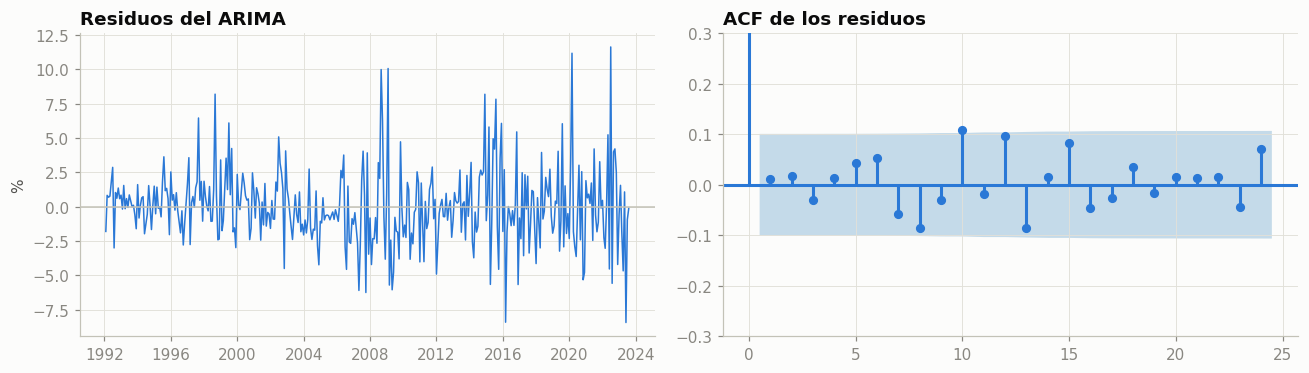

In [7]:
arima = ARIMA(y_ent, order=(P_ARIMA, 1, Q_ARIMA), trend='t').fit()
print(arima.summary().tables[1])

resid = arima.resid.iloc[1:]
lb = acorr_ljungbox(resid, lags=[6, 12, 24], return_df=True)
print('\nPrueba de Ljung-Box sobre los residuos (H0: no hay autocorrelación)')
print(lb.round(3))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].plot(resid * 100, color=AZUL, lw=1); ax[0].axhline(0, color='#c3c2b7', lw=1)
ax[0].set(title='Residuos del ARIMA', ylabel='%')
plot_acf(resid, lags=24, ax=ax[1], color=AZUL, vlines_kwargs={'colors': AZUL}, title='ACF de los residuos')
ax[1].set_ylim(-0.3, 0.3)
plt.tight_layout(); plt.show()

Los residuos no muestran autocorrelación relevante (p-valores de Ljung-Box altos), así que el modelo captura la estructura lineal de la serie. Lo que queda es, en la práctica, ruido: los choques cambiarios no se pueden anticipar con el pasado de la propia TRM.

## 5. El enfoque de Gradient Boosting

Un modelo de árboles no "entiende" el tiempo; hay que convertir la serie en una tabla. Cada fila es un mes y las columnas son información disponible al cierre del mes anterior: los retornos de los últimos 12 meses, su media móvil de 3 meses, su volatilidad de 6 meses y el mes del año.

Un detalle clave: **modelamos el retorno y no el nivel**. Los árboles predicen promedios de valores que ya vieron, así que no pueden extrapolar un nivel de TRM que nunca ocurrió en el entrenamiento. Con el retorno ese problema desaparece, y el nivel se reconstruye como TRM de hoy × exp(retorno predicho).

In [8]:
def tabla_rezagos(ret):
    X = pd.DataFrame({f'rezago_{i}': ret.shift(i) for i in range(1, 13)}, index=ret.index)
    X['media_3m'] = ret.shift(1).rolling(3).mean()
    X['volatilidad_6m'] = ret.shift(1).rolling(6).std()
    X['mes'] = ret.index.month
    return X

X_gb = tabla_rezagos(r)
PARAMS_GB = dict(n_estimators=300, learning_rate=0.03, max_depth=3, subsample=0.8, random_state=SEMILLA)
X_gb.dropna().tail(3).round(4)

,rezago_1,rezago_2,rezago_3,rezago_4,rezago_5,rezago_6,rezago_7,rezago_8,rezago_9,rezago_10,rezago_11,rezago_12,media_3m,volatilidad_6m,mes
fecha,,,,,,,,,,,,,,,
2026-06-01,0.0263,-0.0273,0.0113,-0.0074,-0.0236,0.0014,-0.0239,-0.0114,-0.0314,0.0016,-0.0178,-0.0216,0.0035,0.0206,6
2026-07-01,-0.0591,0.0263,-0.0273,0.0113,-0.0074,-0.0236,0.0014,-0.0239,-0.0114,-0.0314,0.0016,-0.0178,-0.0200,0.0304,7
2026-08-01,-0.0686,-0.0591,0.0263,-0.0273,0.0113,-0.0074,-0.0236,0.0014,-0.0239,-0.0114,-0.0314,0.0016,-0.0338,0.0380,8


## 6. Evaluación con origen móvil

La forma correcta de evaluar un pronóstico es simular cómo se habría usado: en cada uno de los 36 meses de prueba reentrenamos los modelos con toda la información disponible hasta ese momento y pronosticamos solo el mes siguiente. Así ningún modelo "ve el futuro".

In [9]:
fechas_prueba = y.index[-H:]
pred = {'Paseo aleatorio': [], f'ARIMA({P_ARIMA},1,{Q_ARIMA})': [], 'Gradient Boosting': []}

for fecha in fechas_prueba:
    hist = y.loc[:fecha - pd.offsets.MonthBegin(1)]          # información hasta el mes anterior
    ultimo = hist.iloc[-1]
    pred['Paseo aleatorio'].append(ultimo)

    m = ARIMA(hist, order=(P_ARIMA, 1, Q_ARIMA), trend='t').fit()
    pred[f'ARIMA({P_ARIMA},1,{Q_ARIMA})'].append(m.forecast(1).iloc[0])

    Xe = X_gb.loc[:hist.index[-1]].dropna()
    gb = GradientBoostingRegressor(**PARAMS_GB).fit(Xe, r.loc[Xe.index])
    pred['Gradient Boosting'].append(ultimo + gb.predict(X_gb.loc[[fecha]])[0])

real = trm.loc[fechas_prueba]
pred = pd.DataFrame({k: np.exp(v) for k, v in pred.items()}, index=fechas_prueba)

def resumen(p):
    e = real - p
    return pd.Series({'RMSE (COP)': np.sqrt((e ** 2).mean()), 'MAE (COP)': e.abs().mean(),
                      'MAPE (%)': (e.abs() / real).mean() * 100,
                      'Acierto de dirección (%)': (np.sign(p.values - trm.shift(1).loc[fechas_prueba].values)
                                                    == np.sign(real.values - trm.shift(1).loc[fechas_prueba].values)).mean() * 100})

metricas = pred.apply(resumen).T
metricas.loc['Paseo aleatorio', 'Acierto de dirección (%)'] = np.nan   # el paseo aleatorio no predice dirección
metricas['RMSE relativo al paseo aleatorio'] = metricas['RMSE (COP)'] / metricas.loc['Paseo aleatorio', 'RMSE (COP)']
metricas.round(2)

,RMSE (COP),MAE (COP),MAPE (%),Acierto de dirección (%),RMSE relativo al paseo aleatorio
Paseo aleatorio,108.84,86.50,2.23,NaN,1.00
"ARIMA(0,1,1)",115.43,91.01,2.33,50.00,1.06
Gradient Boosting,124.92,99.01,2.53,44.44,1.15


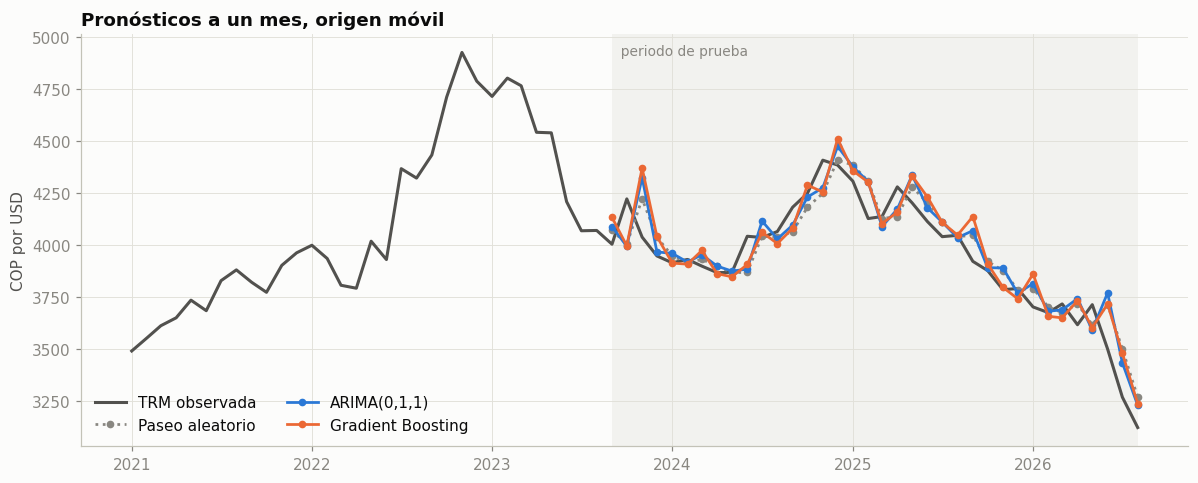

In [10]:
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(trm.loc['2021':], color=TINTA2, lw=2, label='TRM observada')
estilos = {'Paseo aleatorio': (GRIS, ':'), f'ARIMA({P_ARIMA},1,{Q_ARIMA})': (AZUL, '-'), 'Gradient Boosting': (NARANJA, '-')}
for c, (col, ls) in estilos.items():
    ax.plot(pred[c], color=col, ls=ls, lw=1.8, marker='o', ms=4, label=c)
ax.axvspan(fechas_prueba[0], fechas_prueba[-1], color='#e1e0d9', alpha=0.35, lw=0)
ax.text(fechas_prueba[0], ax.get_ylim()[1] * 0.99, '  periodo de prueba', va='top', color=GRIS, fontsize=9)
ax.set(title='Pronósticos a un mes, origen móvil', ylabel='COP por USD')
ax.legend(loc='lower left', ncol=2); plt.tight_layout(); plt.show()

### ¿Las diferencias son significativas?

La prueba de Diebold-Mariano compara los errores de dos pronósticos. La hipótesis nula es que ambos tienen la misma precisión esperada; usamos pérdida cuadrática y la corrección para muestras pequeñas de Harvey, Leybourne y Newbold (1997).

In [11]:
def diebold_mariano(real, p1, p2, h=1):
    d = (real - p1) ** 2 - (real - p2) ** 2
    n = len(d); dbar = d.mean()
    gamma = [np.sum((d[k:] - dbar) * (d[:n - k] - dbar)) / n for k in range(h)]
    var = (gamma[0] + 2 * sum(gamma[1:])) / n
    dm = dbar / np.sqrt(var) * np.sqrt((n + 1 - 2 * h + h * (h - 1) / n) / n)
    return dm, 2 * stats.t.sf(abs(dm), df=n - 1)

nombres = list(pred.columns)
filas = []
for a, b in [(nombres[1], nombres[0]), (nombres[2], nombres[0]), (nombres[2], nombres[1])]:
    dm, p = diebold_mariano(real.values, pred[a].values, pred[b].values)
    filas.append({'comparación': f'{a} vs {b}', 'estadístico DM': dm, 'p-valor': p})
pd.DataFrame(filas).round(3)

,comparación,estadístico DM,p-valor
0,"ARIMA(0,1,1) vs Paseo aleatorio",0.781,0.440
1,Gradient Boosting vs Paseo aleatorio,1.527,0.136
2,"Gradient Boosting vs ARIMA(0,1,1)",1.488,0.146


**El resultado central:** ni el ARIMA ni el Gradient Boosting le ganan al paseo aleatorio. El RMSE del ARIMA es 6 % mayor y el del Gradient Boosting 15 % mayor, y aun así ninguna de las diferencias es estadísticamente significativa (p-valores de Diebold-Mariano por encima de 0,1). Tampoco anticipan bien la dirección del movimiento: el ARIMA acierta si el dólar sube o baja la mitad de las veces, igual que una moneda al aire. Es un resultado clásico en finanzas (Meese y Rogoff, 1983): el tipo de cambio se comporta casi como una caminata aleatoria, porque toda la información disponible ya está incorporada en el precio de hoy. El MA(1) que encontramos es real, pero es un artefacto del promedio mensual y su poder predictivo es muy pequeño frente al tamaño de los choques.

El Gradient Boosting, con más flexibilidad, tiende a sobreajustar patrones de rezagos que no se repiten. Más complejidad no compra precisión cuando la señal es débil.

## 7. Pronóstico para los próximos 12 meses

Con toda la serie reentrenamos ambos modelos y proyectamos hasta agosto de 2027. El ARIMA ofrece intervalos de predicción; para el Gradient Boosting hacemos un pronóstico recursivo (cada predicción alimenta los rezagos del mes siguiente).

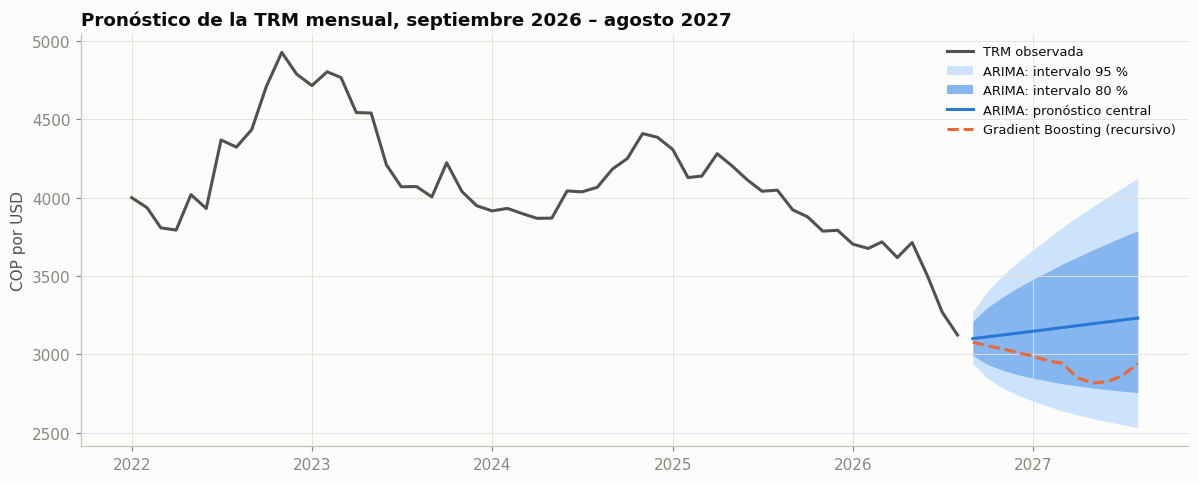

,ARIMA central,IC95 inferior,IC95 superior,Gradient Boosting
2026-09,3100.0,2938.0,3272.0,3077.0
2026-10,3112.0,2845.0,3404.0,3054.0
2026-11,3124.0,2785.0,3503.0,3035.0
2026-12,3136.0,2739.0,3590.0,3011.0
2027-01,3147.0,2701.0,3668.0,2988.0
2027-02,3159.0,2668.0,3741.0,2957.0
2027-03,3171.0,2639.0,3810.0,2944.0
2027-04,3183.0,2614.0,3876.0,2850.0
2027-05,3195.0,2591.0,3940.0,2817.0
2027-06,3207.0,2570.0,4002.0,2825.0


In [12]:
PASOS = 12
m_final = ARIMA(y, order=(P_ARIMA, 1, Q_ARIMA), trend='t').fit()
f = m_final.get_forecast(PASOS)
futuro = pd.date_range(y.index[-1] + pd.offsets.MonthBegin(1), periods=PASOS, freq='MS')
arima_media = np.exp(f.predicted_mean)
ic80 = np.exp(f.conf_int(alpha=0.20)); ic95 = np.exp(f.conf_int(alpha=0.05))

Xe = X_gb.dropna()
gb_final = GradientBoostingRegressor(**PARAMS_GB).fit(Xe, r.loc[Xe.index])
r_ext, nivel, gb_media = r.copy(), y.iloc[-1], []
for fecha in futuro:
    r_ext.loc[fecha] = np.nan
    fila = tabla_rezagos(r_ext).loc[[fecha]]
    paso = gb_final.predict(fila)[0]
    r_ext.loc[fecha] = paso; nivel += paso; gb_media.append(np.exp(nivel))

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(trm.loc['2022':], color=TINTA2, lw=2, label='TRM observada')
ax.fill_between(futuro, ic95.iloc[:, 0], ic95.iloc[:, 1], color='#cde2fb', lw=0, label='ARIMA: intervalo 95 %')
ax.fill_between(futuro, ic80.iloc[:, 0], ic80.iloc[:, 1], color='#86b6ef', lw=0, label='ARIMA: intervalo 80 %')
ax.plot(futuro, arima_media.values, color=AZUL, lw=2, label='ARIMA: pronóstico central')
ax.plot(futuro, gb_media, color=NARANJA, lw=2, ls='--', label='Gradient Boosting (recursivo)')
ax.set(title='Pronóstico de la TRM mensual, septiembre 2026 – agosto 2027', ylabel='COP por USD')
ax.legend(loc='upper right', fontsize=8.5); plt.tight_layout(); plt.show()

pd.DataFrame({'ARIMA central': arima_media.values, 'IC95 inferior': ic95.iloc[:, 0].values,
              'IC95 superior': ic95.iloc[:, 1].values, 'Gradient Boosting': gb_media},
             index=futuro.strftime('%Y-%m')).round(0)

El ARIMA proyecta una línea casi plana con una leve deriva al alza (su deriva refleja la devaluación promedio de 30 años), es decir, dice poco más que "la TRM seguirá cerca de su nivel actual". El Gradient Boosting recursivo, en cambio, prolonga la caída de los últimos meses: como cada predicción alimenta los rezagos siguientes, el impulso reciente se arrastra en el tiempo. Ninguna de las dos trayectorias debe leerse como una predicción firme. Lo informativo es el **ancho del intervalo**: a doce meses, el intervalo del 95 % del ARIMA va aproximadamente de 2.500 a 4.100 pesos. Esa incertidumbre es el mensaje honesto que hay que comunicar a quien use el pronóstico.

## 8. Conclusiones

La TRM mensual se describe bien con un ARIMA(0,1,1): los retornos se comportan casi como ruido, con una pequeña autocorrelación de primer orden que viene del promedio mensual. En una evaluación justa con origen móvil, ni el ARIMA ni el Gradient Boosting superan de forma significativa al paseo aleatorio. La lección metodológica vale más que el pronóstico: siempre hay que comparar contra un modelo ingenuo y evaluar con la información que realmente habría estado disponible.

## Retos para los estudiantes

1. Cambie el horizonte a 3 y 6 meses (pronóstico directo o recursivo). ¿Alguno de los modelos empieza a superar al paseo aleatorio?
2. Agregue como variables del Gradient Boosting los cambios de la tasa IBR (archivo `Tasas de interés.csv` del repositorio de origen, desde 2008). ¿Mejora el pronóstico?
3. Repita el ejercicio con una serie con estacionalidad marcada, por ejemplo el IPC mensual o las exportaciones del DANE, usando SARIMA. ¿Cambia la conclusión sobre ARIMA frente a Gradient Boosting?
4. Reemplace `GradientBoostingRegressor` por `XGBRegressor` o `LGBMRegressor` y ajuste sus hiperparámetros con validación de series de tiempo (`TimeSeriesSplit`).

**Referencias:** Diebold, F. y Mariano, R. (1995), *Journal of Business & Economic Statistics*; Harvey, D., Leybourne, S. y Newbold, P. (1997), *International Journal of Forecasting*; Meese, R. y Rogoff, K. (1983), *Journal of International Economics*; Working, H. (1960), *Econometrica*.